<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-069a-spsa-adam.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 069a. SPSA and Adam for gradients from few circuit runs

A variational circuit is trained by gradient descent on its energy, and on a quantum device every energy is an average over a finite number of measured bit strings. The parameter-shift rule gives the exact derivative with respect to one angle from two runs of the circuit, with that angle shifted by $\pm\pi/2$ and all other angles fixed. A circuit with $n$ angles therefore needs $2n$ runs for one gradient, and for tens or hundreds of angles the number of circuit runs limits the training. Simultaneous-perturbation stochastic approximation (SPSA), introduced by Spall [1], shifts all angles at once along a random direction and estimates every component of the gradient from only two runs, whatever the number of angles. The estimate is noisy and slightly biased, so training needs more updates. SPSA has been used to train hardware-efficient circuits on superconducting qubits [2].

We are given the six-qubit transverse-field Ising chain at its critical point, a hardware-efficient circuit with $n=60$ angles, and measurements of all qubits in the $z$ basis or in the $x$ basis, each repeated a finite number of times. We compute the parameter-shift gradient and its cost, derive the SPSA estimate and test its mean, bias and variance. We then write SPSA with Spall's gain sequences [3] and Adam [4] fed with SPSA gradients, and count the circuit runs each optimiser needs to bring the energy within a fixed distance of the exact ground-state energy.

Sections 1 to 9 form the core route, which runs in about ten minutes on a laptop CPU, most of it in the training runs of Section 9. Section 10, for work at home, scans the perturbation size of SPSA and takes about two minutes more.

Quantities called exact come from the state vector, which a simulation knows and a device does not. Quantities called estimated come from simulated measurement records with fixed random seeds, in the form a device would return them. The optimisers use only estimated energies, and the exact energy is recorded alongside to judge the result.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`. JAX applies the gates, differentiates the energy and draws random numbers on the CPU, NumPy diagonalises the Hamiltonian, and Matplotlib draws the figures. The cells run in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # small calculations; the CPU avoids GPU memory allocation
import json, time
from functools import partial
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 10, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
# course palette: parameter shift blue, SPSA with Adam orange, SPSA with gains green, exact black
COL = dict(ps="#005CA7", sa="#D35A05", sp="#1B7F36", exact="black", grey="#5A6270", light="#9AA0A6", navy="#002B5C")
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
started = time.perf_counter()
NUMBERS = {}
def sci(x, digits=1):
    # LaTeX form of a number in scientific notation for the macro file, e.g. 1.1\times10^{5} (used in math mode)
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
key = jax.random.PRNGKey(691)
print("JAX", jax.__version__, "devices", jax.devices())

JAX 0.11.0 devices [CpuDevice(id=0)]


## 2. The Ising chain and the hardware-efficient circuit

The running model is the open transverse-field Ising chain of $N=6$ spins,
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i , \tag{1}$$
at the critical point $h=J=1$. The first term favours neighbouring spins aligned along $z$, the second term turns every spin towards $+x$, and the two terms do not commute. The Hamiltonian is a $64\times64$ matrix, so its ground-state energy $E_0$, the first excited level $E_1$ and the gap $\Delta E=E_1-E_0$ follow from exact diagonalisation.

The trial state is prepared by the hardware-efficient ansatz (HEA). Starting from $|0\dots0\rangle$, each of its $L$ layers applies $\hat R_y(\theta)$ and then $\hat R_z(\theta)$ with independent angles on every qubit, followed by controlled-$\hat Z$ gates $\widehat{\mathrm{CZ}}$ on the neighbouring pairs $(0,1),\dots,(N-2,N-1)$. A final rotation block ends the circuit, so the number of angles is
$$n=2N(L+1) , \tag{2}$$
and $L=4$ gives $n=60$. The rotations are $\hat R_P(\theta)=e^{-i\theta\hat P/2}=\cos\frac\theta2\,\hat I-i\sin\frac\theta2\,\hat P$ for $\hat P=\hat Y,\hat Z$. The sketch shows the circuit for four qubits.

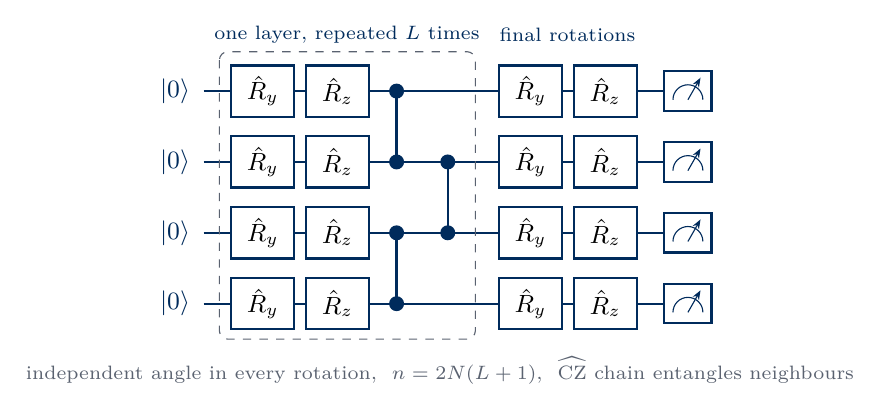

*Hardware-efficient ansatz on four qubits, with $\hat R_y\hat R_z$ rotation blocks, a $\widehat{\mathrm{CZ}}$ chain in every layer and a final rotation block.*

The simulator stores the state as a tensor with one index of size two per qubit. A rotation block multiplies every index by its own $2\times2$ matrix in one tensor contraction, and the $\widehat{\mathrm{CZ}}$ chain multiplies the amplitude of the bit string $\mathbf b=b_0b_1\dots b_{N-1}$ by $(-1)^{\sum_qb_qb_{q+1}}$. We check the circuit once against the same gates written as $64\times64$ Kronecker products.

In [2]:
N, L, J, h = 6, 4, 1.0, 1.0
n = 2 * N * (L + 1)                                   # equation (2)
PAULI = {"I": np.eye(2), "X": np.array([[0, 1], [1, 0]]), "Z": np.diag([1.0, -1.0])}

def pauli_string(factors):
    # Kronecker product over qubits 0..N-1 (qubit 0 leftmost); factors = {qubit: "X" or "Z"}
    out = np.eye(1)
    for q in range(N):
        out = np.kron(out, PAULI[factors.get(q, "I")])
    return out

H_dense = (sum(-J * pauli_string({i: "Z", i + 1: "Z"}) for i in range(N - 1))
           + sum(-h * pauli_string({i: "X"}) for i in range(N)))          # equation (1)
evals, evecs = np.linalg.eigh(H_dense)
E0, E1 = float(evals[0]), float(evals[1]); gap = E1 - E0
psi_ground = evecs[:, 0]

I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE); Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
HAD = (X + Z) / jnp.sqrt(2.0)                                            # Hadamard gate

def rotation(P, theta):
    return jnp.cos(theta / 2) * I2 - 1j * jnp.sin(theta / 2) * P       # exp(-i theta P / 2)

bits = np.indices((2,) * N)                                              # bits[q] = b_q on every basis state
CZ_SIGN = jnp.asarray((-1.0) ** sum(bits[q] * bits[q + 1] for q in range(N - 1)))
CONTRACT = "aA,bB,cC,dD,eE,fF,ABCDEF->abcdef"                            # one 2x2 matrix on each of the six qubits

def apply_all(mats, psi):
    return jnp.einsum(CONTRACT, *mats, psi, optimize="greedy")

def rotation_block(psi, angles):
    # angles[q] = (R_y angle, R_z angle) of qubit q; R_y acts first
    return apply_all([rotation(Z, angles[q, 1]) @ rotation(Y, angles[q, 0]) for q in range(N)], psi)

def hea_state(theta):
    th = theta.reshape(L + 1, N, 2)
    psi = jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)
    for layer in range(L):
        psi = rotation_block(psi, th[layer]) * CZ_SIGN
    return rotation_block(psi, th[L])

def born_probabilities(theta):
    # Born distributions of the z setting and of the x setting (Hadamard on every qubit before the z measurement)
    psi = hea_state(theta)
    return jnp.abs(psi.reshape(-1)) ** 2, jnp.abs(apply_all([HAD] * N, psi).reshape(-1)) ** 2

zsign = jnp.asarray((-1.0) ** bits)
E_Z_VALUES = (-J * sum(zsign[i] * zsign[i + 1] for i in range(N - 1))).reshape(-1)   # e_Z(b)
E_X_VALUES = (-h * zsign.sum(axis=0)).reshape(-1)                                    # e_X(b)

def energy(theta):
    # exact energy: each setting contributes the average of its bit-string values over its Born distribution
    pz, px = born_probabilities(theta)
    return pz @ E_Z_VALUES + px @ E_X_VALUES

# check against the circuit written as 64 x 64 Kronecker products, gate by gate
key, k = jax.random.split(key)
theta_r = jax.random.uniform(k, (n,), minval=-jnp.pi, maxval=jnp.pi)         # random angles used in Sections 4 and 5
def kron_all(mats):
    out = mats[0]
    for m_ in mats[1:]:
        out = np.kron(out, m_)
    return out
psi_k = np.zeros(2 ** N, complex); psi_k[0] = 1.0
th = np.asarray(theta_r).reshape(L + 1, N, 2)
for layer in range(L + 1):
    psi_k = kron_all([np.asarray(rotation(Z, th[layer, q, 1]) @ rotation(Y, th[layer, q, 0])) for q in range(N)]) @ psi_k
    if layer < L:
        psi_k = np.asarray(CZ_SIGN).reshape(-1) * psi_k
assert np.allclose(psi_k, np.asarray(hea_state(theta_r)).reshape(-1), atol=TOL)
assert abs(float(energy(theta_r)) - np.real(psi_k.conj() @ H_dense @ psi_k)) < 1e-10
print(f"N = {N}, L = {L}, n = {n} angles;  E0 = {E0:.6f}, E1 = {E1:.6f}, gap = {gap:.4f}")
print(f"random angles: E = {float(energy(theta_r)):.6f} (einsum circuit) = {np.real(psi_k.conj() @ H_dense @ psi_k):.6f} (Kronecker products)")
NUMBERS.update(N=f"{N}", L=f"{L}", NParams=f"{n}", EZero=f"{E0:.4f}", Gap=f"{gap:.3f}")

N = 6, L = 4, n = 60 angles;  E0 = -7.296230, E1 = -6.814083, gap = 0.4821
random angles: E = 0.896729 (einsum circuit) = 0.896729 (Kronecker products)


## 3. Energies from a finite number of shots and the cost of a circuit run

The Hamiltonian (1) is measured in two settings. In the $z$ setting every qubit is measured in the computational basis and the bit string $\mathbf b$ gives the value $e_Z(\mathbf b)=-J\sum_i(-1)^{b_i+b_{i+1}}$ of the first term. In the $x$ setting a Hadamard gate $\hat H$ precedes the measurement of every qubit, since $\hat H\hat X\hat H=\hat Z$, and the bit string gives $e_X(\mathbf b)=-h\sum_i(-1)^{b_i}$. (The letter $\hat H$ denotes the Hadamard gate, and $\hat{\mathcal H}$ the Hamiltonian.) With $M$ shots in each of the $G=2$ settings the energy is estimated by the sample means
$$\tilde E(\boldsymbol\theta)=\frac1M\sum_{s=1}^Me_Z(\mathbf b^{(s)})+\frac1M\sum_{s=1}^Me_X(\mathbf b'^{(s)}) , \tag{3}$$
where $\mathbf b^{(s)}$ and $\mathbf b'^{(s)}$ are drawn from the Born distributions of the two settings. Its standard error is
$$\sigma_{\tilde E}=\sqrt{\frac{\sigma_Z^2+\sigma_X^2}{M}} , \tag{4}$$
where $\sigma_g^2$ is the variance of $e_g(\mathbf b)$ over the Born distribution of setting $g$, the variance of a single shot.

We call one set of angles, prepared and measured in all settings, a *circuit configuration*. It consumes
$$S=G\,M \tag{5}$$
shots. On a device the number of configurations counts how often the control electronics must be reprogrammed and the circuit re-run, and $S$ times this number counts the total measurement time. All costs below are given in configurations, with the shots following from equation (5). We use $M=1000$ shots per setting, so $S=2000$.

We draw bit strings by inverse-transform sampling, in which a uniform random number selects the first basis state whose cumulative probability exceeds it. We repeat the estimate 2000 times at the random angles and check that the estimates scatter around the exact energy with the standard error (4).

In [3]:
G_SETTINGS, M_SHOTS = 2, 1000
S_SHOTS = G_SETTINGS * M_SHOTS                                           # equation (5)

def sample_mean(key, p, values, shots):
    # mean of `values` over `shots` basis states drawn from the Born distribution p
    cdf = jnp.cumsum(p)
    u = jax.random.uniform(key, (shots,)) * cdf[-1]
    idx = jnp.minimum(jnp.searchsorted(cdf, u, method="compare_all"), p.size - 1)
    return values[idx].mean()

def energy_estimate(key, theta, shots=M_SHOTS):
    # equation (3): one circuit configuration, `shots` bit strings in each of the two settings
    pz, px = born_probabilities(theta)
    kz, kx = jax.random.split(key)
    return sample_mean(kz, pz, E_Z_VALUES, shots) + sample_mean(kx, px, E_X_VALUES, shots)

def shot_variances(theta):
    pz, px = born_probabilities(theta)
    return [float(p @ e ** 2 - (p @ e) ** 2) for p, e in ((pz, E_Z_VALUES), (px, E_X_VALUES))]

key, k = jax.random.split(key)
repeats = jax.jit(jax.vmap(energy_estimate, in_axes=(0, None)))(jax.random.split(k, 2000), theta_r)
sZ2, sX2 = shot_variances(theta_r)
se_pred = np.sqrt((sZ2 + sX2) / M_SHOTS)                                 # equation (4)
E_r = float(energy(theta_r))
assert abs(float(repeats.mean()) - E_r) < 4 * se_pred / np.sqrt(2000)    # no bias
assert abs(float(repeats.std()) / se_pred - 1) < 0.1                     # spread as in equation (4)
print(f"exact E = {E_r:.4f};  mean of 2000 estimates = {float(repeats.mean()):.4f}")
print(f"spread of the estimates = {float(repeats.std()):.4f};  equation (4) = {se_pred:.4f}")
print(f"one circuit configuration = {G_SETTINGS} settings x {M_SHOTS} shots = {S_SHOTS} shots")
NUMBERS.update(Settings=f"{G_SETTINGS}", ShotsPerSetting=f"{M_SHOTS}", ShotsPerConfig=f"{S_SHOTS}", SERand=f"{se_pred:.3f}")

exact E = 0.8967;  mean of 2000 estimates = 0.8976
spread of the estimates = 0.1021;  equation (4) = 0.0990
one circuit configuration = 2 settings x 1000 shots = 2000 shots


## 4. The parameter-shift gradient and its cost

Every angle $\theta_k$ enters one rotation $e^{-i\theta_k\hat P_k/2}$ with $\hat P_k^2=\hat I$, and along this angle alone the energy is a shifted cosine, $E(\theta_k)=a+b\cos(\theta_k-c)$. Two energies at angles shifted by $\pm\pi/2$ give its exact derivative, the parameter-shift rule [5,6]
$$\frac{\partial E}{\partial\theta_k}=\frac{E(\boldsymbol\theta+\tfrac\pi2\mathbf e_k)-E(\boldsymbol\theta-\tfrac\pi2\mathbf e_k)}{2} , \tag{6}$$
where $\mathbf e_k$ is the unit vector along angle $k$. For every component the circuit runs twice, at $\theta_k+\pi/2$ and at $\theta_k-\pi/2$, with all other angles fixed. One gradient therefore costs
$$2n\ \text{configurations}=2nS\ \text{shots} . \tag{7}$$
On a device both energies in equation (6) are estimates (3), and the standard error of one component is $\sigma_{\tilde E}/\sqrt2$. We check equation (6) with exact energies against automatic differentiation (`jax.grad`) and print the cost of one gradient of the 60-angle circuit.

In [4]:
SHIFTS = (jnp.pi / 2) * jnp.eye(n)

def parameter_shift_exact(theta):
    e = jax.vmap(energy)(jnp.concatenate([theta + SHIFTS, theta - SHIFTS]))   # 2n circuit configurations
    return (e[:n] - e[n:]) / 2                                                  # equation (6)

def parameter_shift_estimate(key, theta, shots=M_SHOTS):
    configs = jnp.concatenate([theta + SHIFTS, theta - SHIFTS])
    e = jax.vmap(energy_estimate, in_axes=(0, 0, None))(jax.random.split(key, 2 * n), configs, shots)
    return (e[:n] - e[n:]) / 2

g_exact = np.asarray(jax.jit(jax.grad(energy))(theta_r))
g_ps = np.asarray(jax.jit(parameter_shift_exact)(theta_r))
assert np.max(np.abs(g_ps - g_exact)) < 1e-12
print(f"parameter shift vs jax.grad, largest difference over {n} components: {np.max(np.abs(g_ps - g_exact)):.1e}")
print(f"one parameter-shift gradient: 2n = {2 * n} configurations = {2 * n * S_SHOTS:,} shots")
NUMBERS.update(PSPerStep=f"{2 * n}", PSShotsPerStep=f"{2 * n * S_SHOTS}", PSShotsPerStepSci=sci(2 * n * S_SHOTS))

parameter shift vs jax.grad, largest difference over 60 components: 7.8e-16
one parameter-shift gradient: 2n = 120 configurations = 240,000 shots


## 5. The SPSA estimate of the gradient

SPSA [1] draws a random vector $\boldsymbol\Delta=(\Delta_1,\dots,\Delta_n)$ whose entries are independent and equal to $+1$ or $-1$ with probability $1/2$ each, the Rademacher distribution. Averages over this distribution, written $\langle\cdot\rangle_{\boldsymbol\Delta}$, obey
$$\langle\Delta_k\rangle_{\boldsymbol\Delta}=0,\qquad\langle\Delta_k\Delta_j\rangle_{\boldsymbol\Delta}=\delta_{kj},\qquad\Delta_k^2=1 . \tag{8}$$
All angles are shifted at once by $\pm c\boldsymbol\Delta$ with a perturbation size $c>0$, and the two configurations are measured. A Taylor expansion of the energy around $\boldsymbol\theta$, in which the even orders cancel in the difference, gives the slope along $\boldsymbol\Delta$,
$$\frac{E(\boldsymbol\theta+c\boldsymbol\Delta)-E(\boldsymbol\theta-c\boldsymbol\Delta)}{2c}=\sum_j\Delta_j\,\partial_jE+\frac{c^2}{6}\sum_{j,l,m}\Delta_j\Delta_l\Delta_m\,\partial_j\partial_l\partial_mE+O(c^4) , \tag{9}$$
with $\partial_j=\partial/\partial\theta_j$. SPSA multiplies this single number by $1/\Delta_k=\Delta_k$ and uses it as the estimate of every component,
$$\tilde g_k=\frac{\tilde E(\boldsymbol\theta+c\boldsymbol\Delta)-\tilde E(\boldsymbol\theta-c\boldsymbol\Delta)}{2c}\,\Delta_k ,\qquad k=1,\dots,n . \tag{10}$$
The whole gradient costs
$$2\ \text{configurations}=2S\ \text{shots} , \tag{11}$$
for any number of angles. The sketch compares the configurations of equations (7) and (11).

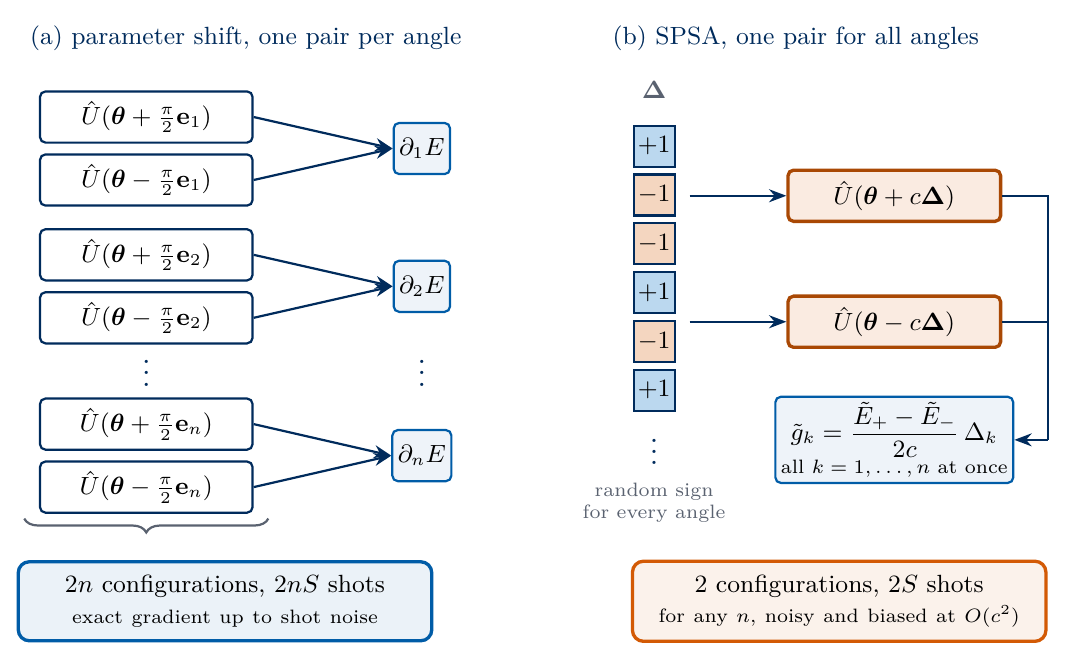

*(a) The parameter-shift rule needs a pair of configurations for every angle. (b) SPSA shifts all angles along one random sign vector and needs one pair of configurations for the whole gradient.*

Averaging equation (10) with exact energies over $\boldsymbol\Delta$ and using equation (8) gives
$$\langle\tilde g_k\rangle_{\boldsymbol\Delta}=\sum_j\langle\Delta_k\Delta_j\rangle_{\boldsymbol\Delta}\,\partial_jE+O(c^2)=\partial_kE+O(c^2) . \tag{12}$$
The mean therefore equals the gradient up to a bias of order $c^2$ from the third derivatives in equation (9), and shot noise, which has zero mean, adds no bias. The leading term of a single estimate is $\partial_kE+\sum_{j\ne k}\Delta_k\Delta_j\,\partial_jE$, a sum of uncorrelated random signs, and the two energy estimates contribute the shot noise of equation (4), so
$$\mathrm{Var}(\tilde g_k)=\sum_{j\ne k}(\partial_jE)^2+\frac{\sigma_{\tilde E}^2}{2c^2} . \tag{13}$$
The first term grows with the number of angles and the second with $1/c^2$, whereas the bias grows with $c^2$.

We test these three statements at the random angles $\boldsymbol\theta_r$. Panel (a) shows the difference between the left-hand side of equation (9) and the exact slope $\sum_j\Delta_j\partial_jE$ for one fixed $\boldsymbol\Delta$, which should fall as $c^2$. Panel (b) averages $K$ estimates (10) from exact energies and shows the relative distance of the average from the exact gradient, which should fall as $K^{-1/2}$ towards the small bias. The printed numbers compare the variance of 4000 estimates with equation (13), once with exact energies and once with $M=1000$ shots.

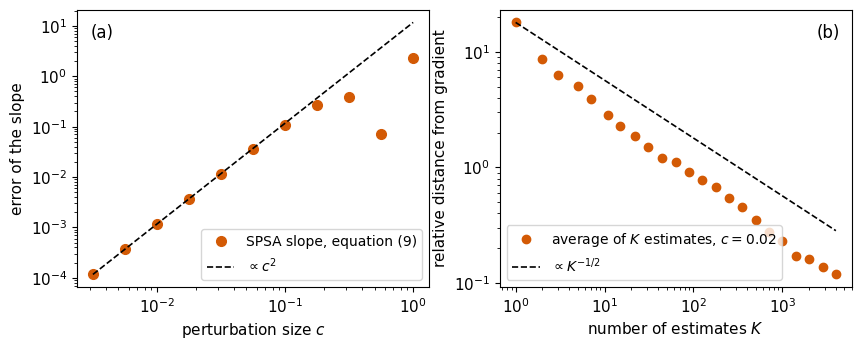

(a) fitted power of c in the slope error: 1.98
(b) relative distance after 1 estimate: 17.96, after 4000 estimates: 0.119
variance of single estimates / equation (13), averaged over the 60 components: exact energies 1.012, M = 1000 shots and c = 0.02: 1.005, exact energies at c = 0.1: 0.861
|grad E|^2 = 16.051;  shot-noise term sigma^2/(2c^2) = 12.241


In [5]:
def rademacher(key, size):
    return 2.0 * jax.random.bernoulli(key, 0.5, (size,)) - 1.0             # entries +1 or -1, probability 1/2 each

def spsa_exact(key, theta, c):
    D = rademacher(key, theta.size)
    return (energy(theta + c * D) - energy(theta - c * D)) / (2 * c) * D   # equation (10) with exact energies

def spsa_estimate(key, theta, c, shots=M_SHOTS):
    kd, kp, km = jax.random.split(key, 3)
    D = rademacher(kd, theta.size)
    e_plus, e_minus = energy_estimate(kp, theta + c * D, shots), energy_estimate(km, theta - c * D, shots)
    return (e_plus - e_minus) / (2 * c) * D                                  # equation (10), two configurations

# (a) bias of the slope along one fixed Delta, equation (9)
key, k = jax.random.split(key)
D_fixed = rademacher(k, n)
slope_exact = float(D_fixed @ g_exact)
c_grid = np.logspace(-2.5, 0, 11)
slope_err = np.array([abs(float((energy(theta_r + c * D_fixed) - energy(theta_r - c * D_fixed)) / (2 * c)) - slope_exact)
                      for c in c_grid])
fit_slope = np.polyfit(np.log(c_grid[:7]), np.log(slope_err[:7]), 1)[0]
assert abs(fit_slope - 2) < 0.1

# (b) average of K estimates with exact energies, c = 0.1
C_TEST, K_MAX = 0.02, 4000
key, k = jax.random.split(key)
g_many = np.asarray(jax.jit(jax.vmap(spsa_exact, in_axes=(0, None, None)))(jax.random.split(k, K_MAX), theta_r, C_TEST))
K_grid = np.unique(np.logspace(0, np.log10(K_MAX), 25).astype(int))
running = np.cumsum(g_many, axis=0)[K_grid - 1] / K_grid[:, None]
rel_dist = np.linalg.norm(running - g_exact, axis=1) / np.linalg.norm(g_exact)

# variance of single estimates against equation (13), exact energies and M = 1000 shots
var_pred_exact = np.sum(g_exact ** 2) - g_exact ** 2
var_meas_exact = g_many.var(axis=0)
C_SHOT = 0.02
key, k = jax.random.split(key)
g_shots = np.asarray(jax.jit(jax.vmap(spsa_estimate, in_axes=(0, None, None)))(jax.random.split(k, K_MAX), theta_r, C_SHOT))
var_pred_shots = var_pred_exact + se_pred ** 2 / (2 * C_SHOT ** 2)
var_meas_shots = g_shots.var(axis=0)
ratio_exact = float(np.mean(var_meas_exact / var_pred_exact)); ratio_shots = float(np.mean(var_meas_shots / var_pred_shots))
# the same test with exact energies at the larger perturbation c = 0.1, where c*sqrt(n) is close to one
key, k = jax.random.split(key)
g_large_c = np.asarray(jax.jit(jax.vmap(spsa_exact, in_axes=(0, None, None)))(jax.random.split(k, K_MAX), theta_r, 0.1))
ratio_large_c = float(np.mean(g_large_c.var(axis=0) / var_pred_exact))
assert abs(ratio_exact - 1) < 0.1 and abs(ratio_shots - 1) < 0.1
assert rel_dist[-1] < 3 * np.sqrt(np.mean(var_pred_exact) * n / K_MAX) / np.linalg.norm(g_exact)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.loglog(c_grid, slope_err, "o", color=COL["sa"], ms=7, label="SPSA slope, equation (9)")
ax1.loglog(c_grid, slope_err[0] * (c_grid / c_grid[0]) ** 2, "--", color=COL["exact"], lw=1.2, label=r"$\propto c^2$")
ax1.set_xlabel(r"perturbation size $c$"); ax1.set_ylabel("error of the slope")
ax1.legend(loc="lower right"); ax1.text(0.04, 0.9, "(a)", transform=ax1.transAxes, fontsize=12)
ax2.loglog(K_grid, rel_dist, "o", color=COL["sa"], ms=6, label=f"average of $K$ estimates, $c={C_TEST}$")
ax2.loglog(K_grid, rel_dist[0] / np.sqrt(K_grid), "--", color=COL["exact"], lw=1.2, label=r"$\propto K^{-1/2}$")
ax2.set_xlabel(r"number of estimates $K$"); ax2.set_ylabel("relative distance from gradient")
ax2.legend(loc="lower left"); ax2.text(0.9, 0.9, "(b)", transform=ax2.transAxes, fontsize=12)
save(fig, "fig_lab069a_spsa_estimator"); plt.show()
print(f"(a) fitted power of c in the slope error: {fit_slope:.2f}")
print(f"(b) relative distance after 1 estimate: {rel_dist[0]:.2f}, after {K_MAX} estimates: {rel_dist[-1]:.3f}")
print(f"variance of single estimates / equation (13), averaged over the {n} components: "
      f"exact energies {ratio_exact:.3f}, M = {M_SHOTS} shots and c = {C_SHOT}: {ratio_shots:.3f}, exact energies at c = 0.1: {ratio_large_c:.3f}")
print(f"|grad E|^2 = {np.sum(g_exact ** 2):.3f};  shot-noise term sigma^2/(2c^2) = {se_pred ** 2 / (2 * C_SHOT ** 2):.3f}")
NUMBERS.update(SlopePower=f"{fit_slope:.2f}", VarRatioExact=f"{ratio_exact:.2f}", VarRatioShots=f"{ratio_shots:.2f}",
               VarRatioLargeC=f"{ratio_large_c:.2f}", RelDistOne=f"{rel_dist[0]:.1f}", RelDistMany=f"{rel_dist[-1]:.2f}", KMax=f"{K_MAX}")

The slope error falls as $c^2$, as equation (9) predicts. A single SPSA estimate lies far from the gradient, on average $\sqrt{n-1}$ times the length of the gradient according to the first term of equation (13), and the average of $K$ estimates approaches the gradient as $K^{-1/2}$. The measured variances agree with equation (13), with exact energies and with $M=1000$ shots. At $c=0.02$ the shot-noise term is comparable to $|\nabla E|^2$ at these angles, and it grows as $1/c^2$ for smaller $c$. The expansion (9) assumes that the whole displacement $c\boldsymbol\Delta$, of length $c\sqrt n$, is small compared with the period $2\pi$ of the cosines. For $n=60$ this length is close to one already at $c=0.1$, where the measured variance falls below equation (13).

## 6. SPSA with Spall's gain sequences

SPSA moves the angles against the estimate (10) with a step size $a_t$ and a perturbation size $c_t$ that both decrease with the update number $t$. Ref. [1] proves convergence to a local minimum when both sequences decrease to zero at suitable rates, and Ref. [3] recommends
$$a_t=\frac{a}{(t+1+A)^{\alpha}},\qquad c_t=\frac{c}{(t+1)^{\gamma}},\qquad\alpha=0.602,\quad\gamma=0.101 , \tag{14}$$
where $a$, $c$ and $A$ are chosen constants. The stability constant $A$ is about one tenth of the planned number of updates and keeps the first steps small. The constant $c$ is chosen large enough that the energy difference of the two configurations exceeds the shot noise $\sigma_{\tilde E}$, and $a$ sets the size of the first steps.

1. Draw $\boldsymbol\Delta$ with independent entries $\pm1$.
2. Set $a_t$ and $c_t$ by equation (14).
3. Measure the configurations $\boldsymbol\theta+c_t\boldsymbol\Delta$ and $\boldsymbol\theta-c_t\boldsymbol\Delta$, which gives $\tilde E_+$ and $\tilde E_-$.
4. Form $\tilde g_k=(\tilde E_+-\tilde E_-)\,\Delta_k/(2c_t)$ for all $k$.
5. Update $\boldsymbol\theta\leftarrow\boldsymbol\theta-a_t\tilde{\mathbf g}$.

We run $T$ such updates inside a compiled `jax.lax.scan`, and every `CHUNK` updates we record the exact energy $E(\boldsymbol\theta)$ from the state vector. The optimiser never sees it.

In [6]:
CHUNK = 20                                                     # updates between two records of the exact energy

def run_spsa_gains(key, theta0, steps, a, c, A):
    def update(carry, t):
        theta, key = carry
        key, k = jax.random.split(key)
        a_t, c_t = a / (t + 1 + A) ** 0.602, c / (t + 1) ** 0.101          # equation (14)
        return (theta - a_t * spsa_estimate(k, theta, c_t), key), None
    def chunk(carry, t0):
        carry, _ = jax.lax.scan(update, carry, t0 + jnp.arange(CHUNK))
        return carry, energy(carry[0])                                     # exact energy, for the record only
    _, record = jax.lax.scan(chunk, (theta0, key), CHUNK * jnp.arange(steps // CHUNK))
    return record

## 7. Adam fed with SPSA gradients

Adam [4] keeps, for every angle, running averages of the gradient and of its square,
$$m_k\leftarrow\beta_1m_k+(1-\beta_1)\,\tilde g_k,\qquad v_k\leftarrow\beta_2v_k+(1-\beta_2)\,\tilde g_k^2 , \tag{15}$$
and moves each angle by
$$\theta_k\leftarrow\theta_k-\eta\,\frac{\hat m_k}{\sqrt{\hat v_k}+\epsilon},\qquad\hat m_k=\frac{m_k}{1-\beta_1^{t+1}},\quad\hat v_k=\frac{v_k}{1-\beta_2^{t+1}} , \tag{16}$$
with the standard constants $\beta_1=0.9$, $\beta_2=0.999$ and $\epsilon=10^{-8}$ of Ref. [4] and a step size $\eta$. The hats on $m$ and $v$ mark the correction of the averages for their start at zero. Adam accepts any gradient estimate. With the parameter-shift gradient (6) every update costs $2n$ configurations, and with the SPSA estimate (10) it costs two.

The SPSA estimate of one component changes sign from update to update with the random $\Delta_k$. These flips cancel in the average $m_k$, which follows the mean gradient (12), while $v_k$ measures the size of the noisy estimates. The step of every angle therefore stays close to $\eta$ although a single estimate is large, and Adam runs with fixed $\eta$ and fixed $c$ in place of the sequences (14). The Adam function accepts any gradient estimate, so the same code runs with the parameter-shift gradient and with SPSA.

In [7]:
B1, B2, EPS = 0.9, 0.999, 1e-8

def adam_step(theta, m, v, g, t, lr):
    m = B1 * m + (1 - B1) * g                                  # equation (15)
    v = B2 * v + (1 - B2) * g ** 2
    m_hat, v_hat = m / (1 - B1 ** (t + 1)), v / (1 - B2 ** (t + 1))
    return theta - lr * m_hat / (jnp.sqrt(v_hat) + EPS), m, v   # equation (16)

def run_adam(key, theta0, steps, lr, gradient, chunk):
    # gradient(key, theta) returns one gradient estimate; the exact energy is recorded every `chunk` updates
    def update(carry, t):
        theta, m, v, key = carry
        key, k = jax.random.split(key)
        theta, m, v = adam_step(theta, m, v, gradient(k, theta), t, lr)
        return (theta, m, v, key), None
    def block(carry, t0):
        carry, _ = jax.lax.scan(update, carry, t0 + jnp.arange(chunk))
        return carry, energy(carry[0])
    zeros = jnp.zeros_like(theta0)
    _, record = jax.lax.scan(block, (theta0, zeros, zeros, key), chunk * jnp.arange(steps // chunk))
    return record

def run_shift_adam(key, theta0, steps, lr):
    return run_adam(key, theta0, steps, lr, parameter_shift_estimate, 1)

def run_spsa_adam(key, theta0, steps, lr, c):
    return run_adam(key, theta0, steps, lr, lambda k, th: spsa_estimate(k, th, c), CHUNK)

## 8. Configurations per update and the number of angles

Equations (7) and (11) fix the cost of one update. The table lists it for the six-qubit hardware-efficient circuit with $L=1,\dots,6$ layers. The parameter-shift cost grows linearly with the number of angles, while the SPSA cost stays at two configurations. A training run that needs $U$ updates costs $U$ times the entry of the table, so SPSA is cheaper whenever it needs fewer than $n$ times as many updates as the parameter-shift rule.

In [8]:
rows = []
print(" L    n   shift: configs   shots/update   SPSA: configs   shots/update")
for L_ in range(1, 7):
    n_ = 2 * N * (L_ + 1)                                                   # equation (2)
    rows.append((L_, n_, 2 * n_, 2 * n_ * S_SHOTS, 2, 2 * S_SHOTS))
    print(f"{L_:2d}  {n_:3d}   {2 * n_:14d}   {2 * n_ * S_SHOTS:12,d}   {2:13d}   {2 * S_SHOTS:12,d}")
with open(FIG / "tab_lab069a_cost.tex", "w") as f:
    f.write("\\begin{tabular}{@{}rrrrrr@{}}\n\\toprule\n")
    f.write("& & \\multicolumn{2}{c}{parameter shift} & \\multicolumn{2}{c}{SPSA}\\\\\n")
    f.write("$L$ & $n$ & configurations & shots & configurations & shots\\\\\n\\midrule\n")
    for r in rows:
        f.write(f"{r[0]} & {r[1]} & {r[2]} & {r[3]:,} & {r[4]} & {r[5]:,}\\\\\n".replace(",", "\\,"))
    f.write("\\bottomrule\n\\end{tabular}\n")

 L    n   shift: configs   shots/update   SPSA: configs   shots/update
 1   24               48         96,000               2          4,000
 2   36               72        144,000               2          4,000
 3   48               96        192,000               2          4,000
 4   60              120        240,000               2          4,000
 5   72              144        288,000               2          4,000
 6   84              168        336,000               2          4,000


## 9. Circuit runs needed to reach a tolerance

We train the circuit with three optimisers that see only estimated energies with $M=1000$ shots per setting.

- (a) Adam with the parameter-shift gradient (6), $2n=120$ configurations per update,
- (b) Adam with the SPSA estimate (10) at fixed $c$, two configurations per update,
- (c) SPSA with the gain sequences (14), two configurations per update.

All runs start from the same angles, drawn uniformly from $[-0.1,0.1]$, close to the product state $|0\dots0\rangle$ with energy $-J(N-1)=-5$. Each optimiser receives the same budget of about $10^5$ configurations, which is 840 updates for (a) and 50 000 updates for (b) and (c). Five independent seeds of the measurement records and of the random directions show the spread. The step sizes were chosen by a short scan for each optimiser on separate seeds, and the stability constant of (c) is one tenth of its number of updates.

The quality of the result is measured by the exact energy error $E-E_0$. Its tolerance follows from the bound $E-E_0\ge\Delta E\,(1-F)$, which holds because every unit of weight outside the ground state raises the energy by at least the gap. The energy error $E-E_0\le\Delta E/2$ guarantees a fidelity $F\ge1/2$ with the exact ground state, and $E-E_0\le\Delta E/5$ guarantees $F\ge0.8$. We count the configurations, and the corresponding shots, after which each run first falls below these two tolerances.

In [9]:
LR_PS = 0.05                         # (a) Adam step size with parameter-shift gradients
LR_SA, C_SA = 0.005, 0.1        # (b) Adam step size and fixed perturbation size with SPSA gradients
A_SP, C_SP = 0.4, 0.3          # (c) constants a and c of equation (14)
SEEDS = 5
STEPS_PS, STEPS_SPSA = 840, 50_000
A_STAB = 0.1 * STEPS_SPSA                    # stability constant A of equation (14)
key, k = jax.random.split(key)
theta0 = jax.random.uniform(k, (n,), minval=-0.1, maxval=0.1)
seed_keys = jnp.stack([jax.random.PRNGKey(1000 + s) for s in range(SEEDS)])

t0 = time.perf_counter()
rec_ps = np.asarray(jax.jit(jax.vmap(run_shift_adam, in_axes=(0, None, None, None)), static_argnums=2)(
    seed_keys, theta0, STEPS_PS, LR_PS)) - E0
t_ps = time.perf_counter() - t0
rec_sa = np.asarray(jax.jit(jax.vmap(run_spsa_adam, in_axes=(0, None, None, None, None)), static_argnums=2)(
    seed_keys, theta0, STEPS_SPSA, LR_SA, C_SA)) - E0
t_sa = time.perf_counter() - t0 - t_ps
rec_sp = np.asarray(jax.jit(jax.vmap(run_spsa_gains, in_axes=(0, None, None, None, None, None)), static_argnums=2)(
    seed_keys, theta0, STEPS_SPSA, A_SP, C_SP, A_STAB)) - E0
t_sp = time.perf_counter() - t0 - t_ps - t_sa
# configurations executed at each record of the exact energy
x_ps = 2 * n * np.arange(1, STEPS_PS + 1)
x_spsa = 2 * CHUNK * np.arange(1, STEPS_SPSA // CHUNK + 1)
assert np.all(rec_ps > -1e-9) and np.all(rec_sa > -1e-9) and np.all(rec_sp > -1e-9)     # variational bound
print(f"wall time: (a) {t_ps:.0f} s, (b) {t_sa:.0f} s, (c) {t_sp:.0f} s")
print(f"budget: (a) {x_ps[-1]:,} configurations, (b) and (c) {x_spsa[-1]:,} configurations")

wall time: (a) 112 s, (b) 234 s, (c) 197 s
budget: (a) 100,800 configurations, (b) and (c) 100,000 configurations


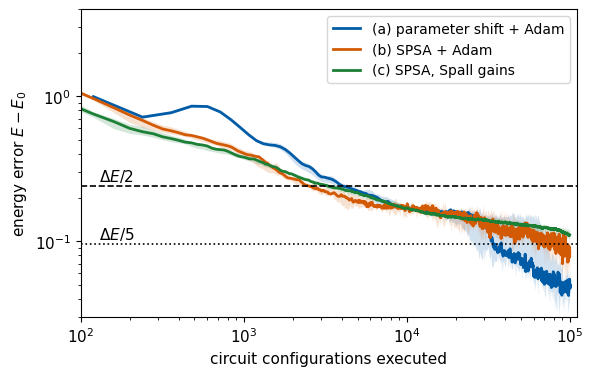

                               configs to dE/2 (5 seeds)                configs to dE/5 (5 seeds)
(a) parameter shift + Adam     [4680, 3720, 4800, 3840, 4080]           [32880, 25440, 33840, 71880, 34200]
(b) SPSA + Adam                [2520, 2520, 2400, 2440, 2880]           [78120, 30280, 56680, 37600, 45920]
(c) SPSA, Spall gains          [3000, 3280, 3520, 3120, 3760]           [None, None, None, None, None]
PS half: median 4,080 configurations = 34 updates = 8.16e+06 shots, range 3,720 to 4,800
PS fifth: median 33,840 configurations = 282 updates = 6.77e+07 shots, range 25,440 to 71,880
PS: final E - E0, median 0.050, range 0.039 to 0.054
SA half: median 2,520 configurations = 1,260 updates = 5.04e+06 shots, range 2,400 to 2,880
SA fifth: median 45,920 configurations = 22,960 updates = 9.18e+07 shots, range 30,280 to 78,120
SA: final E - E0, median 0.086, range 0.063 to 0.104
SP half: median 3,280 configurations = 1,640 updates = 6.56e+06 shots, range 3,000 to 3,760
SP fifth: rea

In [10]:
TOLS = {"half": gap / 2, "fifth": gap / 5}
METHODS = {"PS": ("(a) parameter shift + Adam", rec_ps, x_ps, COL["ps"]),
           "SA": ("(b) SPSA + Adam", rec_sa, x_spsa, COL["sa"]),
           "SP": ("(c) SPSA, Spall gains", rec_sp, x_spsa, COL["sp"])}

def configs_to(rec, x, tol):
    # configurations after which each run first has E - E0 <= tol (None if never within the budget)
    out = []
    for r in rec:
        hit = np.nonzero(r <= tol)[0]
        out.append(int(x[hit[0]]) if hit.size else None)
    return out

fig, ax = plt.subplots(figsize=(6.4, 4.0))
for name, (label, rec, x, col) in METHODS.items():
    ax.fill_between(x, rec.min(axis=0), rec.max(axis=0), color=col, alpha=0.18, lw=0)
    ax.plot(x, np.median(rec, axis=0), color=col, lw=2, label=label)
for tol, ls in ((TOLS["half"], "--"), (TOLS["fifth"], ":")):
    ax.axhline(tol, color=COL["exact"], ls=ls, lw=1.2)
ax.text(1.3e2, TOLS["half"] * 1.08, r"$\Delta E/2$", fontsize=11)
ax.text(1.3e2, TOLS["fifth"] * 1.08, r"$\Delta E/5$", fontsize=11)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(1e2, 1.1e5); ax.set_ylim(3e-2, 4)
ax.set_xlabel("circuit configurations executed"); ax.set_ylabel(r"energy error $E-E_0$")
ax.legend(loc="upper right")
save(fig, "fig_lab069a_comparison"); plt.show()

summary_rows = {}
print(f"{'':30s} {'configs to dE/2 (5 seeds)':40s} {'configs to dE/5 (5 seeds)'}")
for name, (label, rec, x, col) in METHODS.items():
    half, fifth = configs_to(rec, x, TOLS["half"]), configs_to(rec, x, TOLS["fifth"])
    summary_rows[name] = dict(half=half, fifth=fifth, final=rec[:, -1].tolist())
    print(f"{label:30s} {str(half):40s} {fifth}")
for name, row in summary_rows.items():
    per = 2 * n if name == "PS" else 2
    for tag in ("half", "fifth"):
        hits = [v for v in row[tag] if v is not None]
        if len(hits) == SEEDS:
            med = int(np.median(hits))
            NUMBERS[f"{name}Configs{tag.capitalize()}"] = f"{med:,}".replace(",", "\\,")
            NUMBERS[f"{name}Steps{tag.capitalize()}"] = f"{med // per:,}".replace(",", "\\,")
            NUMBERS[f"{name}Shots{tag.capitalize()}"] = sci(med * S_SHOTS)
            NUMBERS[f"{name}Range{tag.capitalize()}"] = f"{min(hits):,}--{max(hits):,}".replace(",", "\\,")
            print(f"{name} {tag}: median {med:,} configurations = {med // per:,} updates = {med * S_SHOTS:.2e} shots, "
                  f"range {min(hits):,} to {max(hits):,}")
        else:
            NUMBERS[f"{name}Reached{tag.capitalize()}"] = f"{len(hits)}"
            print(f"{name} {tag}: reached by {len(hits)} of {SEEDS} seeds within the budget")
    print(f"{name}: final E - E0, median {np.median(row['final']):.3f}, range {min(row['final']):.3f} to {max(row['final']):.3f}")
    NUMBERS[f"{name}Final"] = f"{np.median(row['final']):.2f}"
NUMBERS.update(Seeds=f"{SEEDS}", TolHalf=f"{TOLS['half']:.2f}", TolFifth=f"{TOLS['fifth']:.3f}",
               BudgetPS=f"{x_ps[-1]:,}".replace(",", "\\,"), BudgetSPSA=f"{x_spsa[-1]:,}".replace(",", "\\,"),
               StepsPS=f"{STEPS_PS}", StepsSPSA=f"{STEPS_SPSA:,}".replace(",", "\\,"),
               LrPS=f"{LR_PS}", LrSA=f"{LR_SA}", CSA=f"{C_SA}", ASP=f"{A_SP}", CSP=f"{C_SP}")

All three optimisers reach $\Delta E/2$ within a few thousand configurations, and the two SPSA optimisers get there first. The median run of Adam with SPSA gradients crosses $\Delta E/2$ after about 2500 configurations, SPSA with Spall's gains after about 3300, and Adam with the parameter-shift rule after about 4100. The parameter-shift rule needs only 34 updates for this, whereas SPSA with Adam needs about 1300. SPSA is nevertheless cheaper here, since each of its updates costs two configurations and each parameter-shift update costs 120. The printed table gives the values for every seed.

Adam with the parameter-shift rule reaches the stricter tolerance $\Delta E/5$ first, after a median of about $3.4\times10^4$ configurations, and Adam with SPSA gradients after about $4.6\times10^4$. SPSA with Spall's gains does not reach it within $10^5$ configurations in any of the five runs. Near the minimum the gradient is small while the shot-noise term of equation (13) stays, so the SPSA updates become noisier relative to the descent and their low cost no longer compensates. At the end of the budget the parameter-shift runs have the lowest energy error, and the spread between seeds is large for both Adam variants, from about $2.5\times10^4$ to $7\times10^4$ configurations at $\Delta E/5$. In shots, every configuration costs $S=2000$, so $\Delta E/2$ needs about $5\times10^6$ shots with SPSA and Adam and $8\times10^6$ with the parameter-shift rule. The core route ends here.

## 10. The perturbation size of SPSA (at home)

Equation (13) predicts that a small perturbation size $c$ amplifies the shot noise of an SPSA estimate as $1/c^2$, while equation (12) predicts a bias that grows as $c^2$. We repeat optimiser (b) with three values of $c$, two seeds and half the budget, which takes about two minutes.

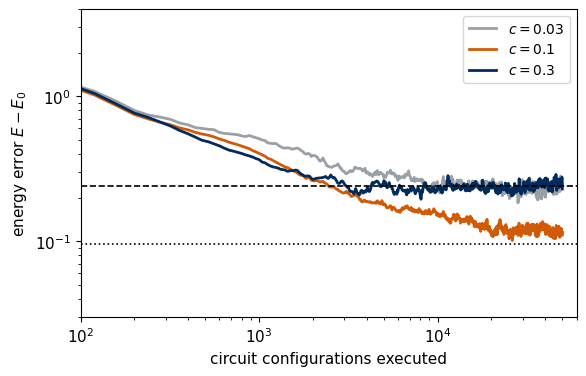

c = 0.03: final E - E0 (median of 2) = 0.245, configurations to dE/2: [10120, 5960]
c = 0.1: final E - E0 (median of 2) = 0.110, configurations to dE/2: [2480, 2360]
c = 0.3: final E - E0 (median of 2) = 0.229, configurations to dE/2: [3240, 2400]
optional section: 94 s


In [11]:
RUN_OPTIONAL = True                          # set to False to skip this section
if RUN_OPTIONAL:
    C_SCAN, SEEDS_SCAN, STEPS_SCAN = (0.03, 0.1, 0.3), 2, 25_000
    x_scan = 2 * CHUNK * np.arange(1, STEPS_SCAN // CHUNK + 1)
    t0 = time.perf_counter()
    scan_keys = jnp.stack([jax.random.PRNGKey(2000 + s) for s in range(SEEDS_SCAN)])
    run_b = jax.jit(jax.vmap(run_spsa_adam, in_axes=(0, None, None, None, None)), static_argnums=2)
    scan = {c: np.asarray(run_b(scan_keys, theta0, STEPS_SCAN, LR_SA, c)) - E0 for c in C_SCAN}
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    for c, col in zip(C_SCAN, (COL["light"], COL["sa"], COL["navy"])):
        ax.plot(x_scan, np.median(scan[c], axis=0), color=col, lw=2, label=f"$c={c}$")
    ax.axhline(TOLS["half"], color=COL["exact"], ls="--", lw=1.2); ax.axhline(TOLS["fifth"], color=COL["exact"], ls=":", lw=1.2)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e2, 6e4); ax.set_ylim(3e-2, 4)
    ax.set_xlabel("circuit configurations executed"); ax.set_ylabel(r"energy error $E-E_0$"); ax.legend(loc="upper right")
    save(fig, "fig_lab069a_c_scan"); plt.show()
    for c in C_SCAN:
        print(f"c = {c}: final E - E0 (median of {SEEDS_SCAN}) = {np.median(scan[c][:, -1]):.3f}, "
              f"configurations to dE/2: {configs_to(scan[c], x_scan, TOLS['half'])}")
    print(f"optional section: {time.perf_counter() - t0:.0f} s")

The perturbation size controls how fast SPSA with Adam descends. With $c=0.03$ the shot-noise term of equation (13) is large, and the runs need several thousand configurations more to reach $\Delta E/2$. With $c=0.3$ the runs reach $\Delta E/2$ about as fast as with $c=0.1$ but end at a larger energy error, since the displacement $c\sqrt n$ is then larger than one and the expansion (9) no longer holds. The value $c=0.1$ used in Section 9 lies between the two regimes.

Finally we store the numbers as LaTeX macros and a JSON summary and print the runtime.

## 11. Exercises

1. Use equation (8) to show that $\langle\Delta_k\Delta_j\Delta_l\Delta_m\rangle_{\boldsymbol\Delta}$ is one when the four indices form equal pairs and zero otherwise. Insert this into the third-order term of equation (9) and show that the bias in equation (12) equals $\frac{c^2}{6}\big[\partial_k^3E+3\sum_{j\ne k}\partial_k\partial_j^2E\big]$.
2. Replace the Rademacher distribution by Gaussian entries $\Delta_k$ of unit variance and use $1/\Delta_k$ in equation (10). Estimate the variance of $\tilde g_k$ numerically and explain the result.
3. Average $K=4$ SPSA estimates per update in optimiser (b), at a cost of $2K$ configurations, and compare the number of configurations needed to reach $\Delta E/2$ with Section 9.
4. Repeat the comparison of Section 9 with $L=2$ layers ($n=36$) and explain how the configurations needed by the parameter-shift rule and by SPSA change.
5. Use the measured variance of the SPSA estimate at $c=0.15$ to find the number of shots per setting $M$ at which the shot-noise term of equation (13) equals $|\nabla E|^2$ at the random angles.

## 12. Summary

On a device the cost of a gradient is counted in circuit runs. The parameter-shift rule runs the circuit twice for every angle, at $\theta_k\pm\pi/2$ with all other angles fixed, so one gradient costs $2n$ circuit configurations and $2nS$ shots. SPSA shifts all angles at once along a random sign vector $\boldsymbol\Delta$ and estimates every component from the same two configurations, so one update costs two configurations and $2S$ shots for any $n$. Averaged over $\boldsymbol\Delta$, the SPSA estimate equals the gradient up to a bias of order $c^2$. A single estimate has a variance equal to the squared gradient without its own component plus the shot noise enhanced by $1/c^2$. Adam accepts SPSA estimates without change, averages out their random signs and runs with a fixed step and a fixed perturbation size. For the six-qubit Ising chain with a 60-angle hardware-efficient circuit, SPSA reaches a moderate energy error with fewer circuit configurations than the parameter-shift rule, although it needs many more updates. Close to the minimum its noise dominates, and the parameter-shift rule reaches a small energy error with fewer configurations. SPSA with Spall's gain sequences descends as fast as SPSA with Adam at first and then slows down.

## References

[1] J. C. Spall, Multivariate stochastic approximation using a simultaneous perturbation gradient approximation, IEEE Trans. Autom. Control **37**, 332 (1992), doi:[10.1109/9.119632](https://doi.org/10.1109/9.119632).

[2] A. Kandala, A. Mezzacapo, K. Temme, M. Takita, M. Brink, J. M. Chow and J. M. Gambetta, Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets, Nature **549**, 242 (2017), doi:[10.1038/nature23879](https://doi.org/10.1038/nature23879).

[3] J. C. Spall, Implementation of the simultaneous perturbation algorithm for stochastic optimization, IEEE Trans. Aerosp. Electron. Syst. **34**, 817 (1998), doi:[10.1109/7.705889](https://doi.org/10.1109/7.705889).

[4] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, arXiv:1412.6980 (2014), [arxiv.org/abs/1412.6980](https://arxiv.org/abs/1412.6980).

[5] K. Mitarai, M. Negoro, M. Kitagawa and K. Fujii, Quantum circuit learning, Phys. Rev. A **98**, 032309 (2018), doi:[10.1103/PhysRevA.98.032309](https://doi.org/10.1103/PhysRevA.98.032309).

[6] M. Schuld, V. Bergholm, C. Gogolin, J. Izaac and N. Killoran, Evaluating analytic gradients on quantum hardware, Phys. Rev. A **99**, 032331 (2019), doi:[10.1103/PhysRevA.99.032331](https://doi.org/10.1103/PhysRevA.99.032331).